<a href="https://colab.research.google.com/github/renatoemanuelbispo/Churn-Teste-de-Hipoteses/blob/main/RFM%2C_Churn_e_Teste_de_Hipoteses.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. INFORMAÇÕES DA BASE E TIPOS DE DADOS (dados_brutos)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 4 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   ID_Cliente            5000 non-null   int64         
 1   Data_Compra           5000 non-null   datetime64[ns]
 2   Valor_Gasto           5000 non-null   float64       
 3   Categorias_Visitadas  5000 non-null   object        
dtypes: datetime64[ns](1), float64(1), int64(1), object(1)
memory usage: 156.4+ KB
None

2. RESUMO ESTATÍSTICO (VALORES NUMÉRICOS)
              count                 mean                  min  \
ID_Cliente   5000.0            1250.6706               1000.0   
Data_Compra    5000  2026-07-06 20:30:00  2026-03-24 17:00:00   
Valor_Gasto  5000.0           146.988948             0.001745   

                             25%                  50%                  75%  \
ID_Cliente           

/tmp/ipykernel_2330/3079294543.py:72: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=dados_brutos, x='Categorias_Visitadas', palette='viridis', order=dados_brutos['Categorias_Visitadas'].value_counts().index)


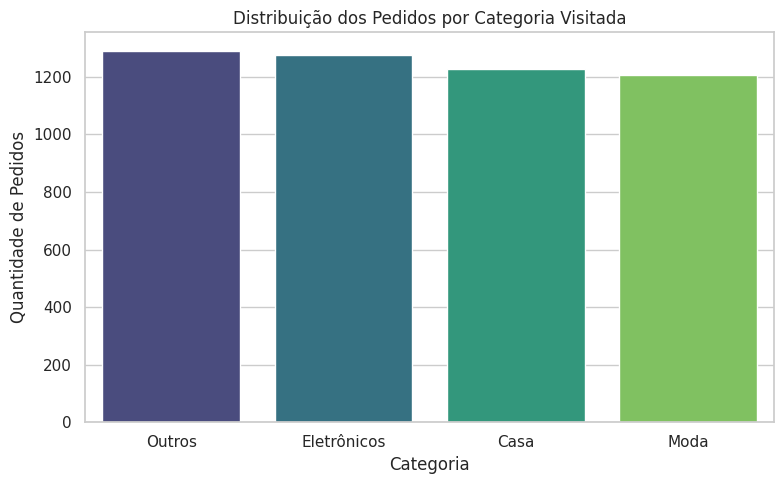

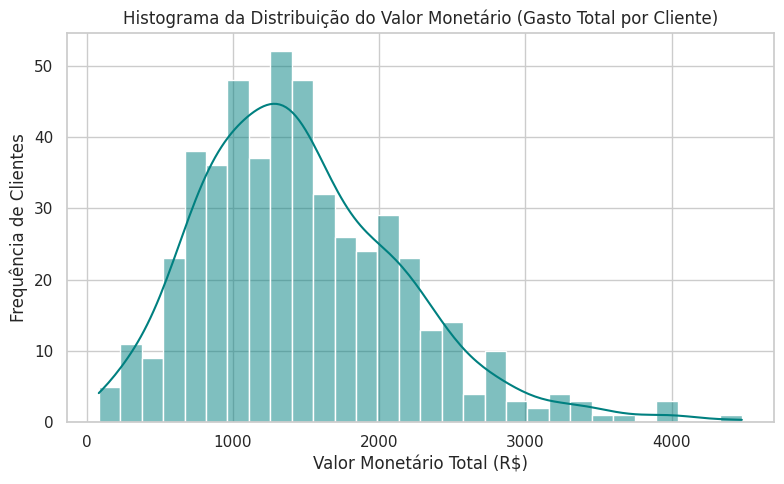

/tmp/ipykernel_2330/3079294543.py:92: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=rfm, x='R_Score', palette='Blues_r')


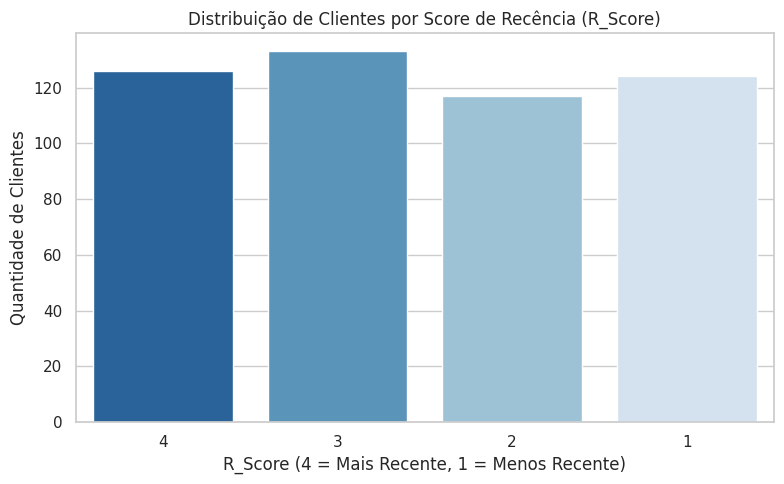

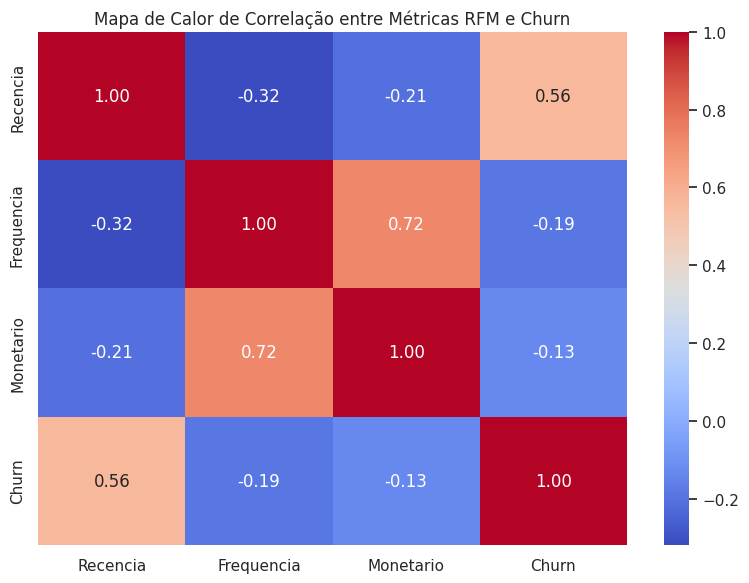

/tmp/ipykernel_2330/3079294543.py:110: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=rfm, x='Churn', y='Monetario', palette='Set2', errorbar=None)


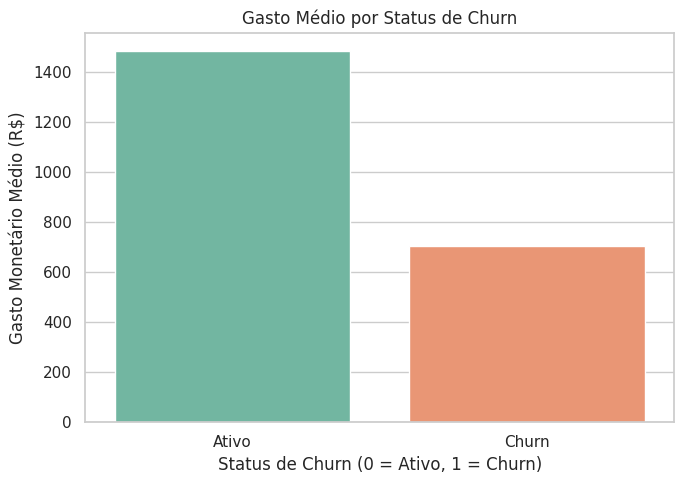


3. TESTE DE HIPÓTESE (T-Test de Welch)
Estatística T: -5.4691
P-Valor:       1.1199e-03

Conclusão: Rejeitamos H0. Há uma diferença estatisticamente significativa no gasto médio entre clientes em Churn e clientes Ativos.


In [1]:
import pandas as pd
import numpy as np
import scipy.stats as stats
import seaborn as sns
import matplotlib.pyplot as plt

# Estilo dos gráficos
sns.set_theme(style="whitegrid")
np.random.seed(42)


# 1. CRIAÇÃO E TRATAMENTO DA BASE DE DADOS

n_pedidos = 5000
data_atual = pd.to_datetime('2026-10-19')

dados_brutos = pd.DataFrame({
    'ID_Cliente': np.random.randint(1000, 1500, n_pedidos),
    'Data_Compra': pd.date_range(end=data_atual, periods=n_pedidos, freq='h'),
    'Valor_Gasto': np.random.exponential(scale=150, size=n_pedidos),
    'Categorias_Visitadas': np.random.choice(['Eletrônicos', 'Moda', 'Casa', None], size=n_pedidos)
})

# Tratamento de Nulos e Consistência
dados_brutos['Categorias_Visitadas'] = dados_brutos['Categorias_Visitadas'].fillna('Outros')
dados_brutos['Valor_Gasto'] = dados_brutos['Valor_Gasto'].abs()


# 2. INSPEÇÃO E ANÁLISE DOS TIPOS DE DADOS

print("="*50)
print("1. INFORMAÇÕES DA BASE E TIPOS DE DADOS (dados_brutos)")
print("="*50)
print(dados_brutos.info())

print("\n" + "="*50)
print("2. RESUMO ESTATÍSTICO (VALORES NUMÉRICOS)")
print("="*50)
print(dados_brutos.describe().T)


# 3. CÁLCULO DAS MÉTRICAS RFM

rfm = dados_brutos.groupby('ID_Cliente').agg({
    'Data_Compra': lambda x: (data_atual - x.max()).days, # Recência (dias)
    'ID_Cliente': 'count',                                # Frequência (compras)
    'Valor_Gasto': 'sum'                                  # Valor Monetário ($)
}).rename(columns={
    'Data_Compra': 'Recencia',
    'ID_Cliente': 'Frequencia',
    'Valor_Gasto': 'Monetario'
})

# Criação dos Scores RFM (1 a 4 por Quartil)
rfm['R_Score'] = pd.qcut(rfm['Recencia'], q=4, labels=[4, 3, 2, 1])
rfm['F_Score'] = pd.qcut(rfm['Frequencia'].rank(method='first'), q=4, labels=[1, 2, 3, 4])
rfm['M_Score'] = pd.qcut(rfm['Monetario'], q=4, labels=[1, 2, 3, 4])

rfm['RFM_Cell'] = rfm['R_Score'].astype(str) + rfm['F_Score'].astype(str) + rfm['M_Score'].astype(str)


# 4. DEFINIÇÃO DA REGRA DE CHURN

rfm['Churn'] = np.where(rfm['Recencia'] > 90, 1, 0)


# 5. VISUALIZAÇÕES E GRÁFICOS


# 5.1 Frequência por Categorias Visitadas
plt.figure(figsize=(8, 5))
sns.countplot(data=dados_brutos, x='Categorias_Visitadas', palette='viridis', order=dados_brutos['Categorias_Visitadas'].value_counts().index)
plt.title('Distribuição dos Pedidos por Categoria Visitada')
plt.xlabel('Categoria')
plt.ylabel('Quantidade de Pedidos')
plt.tight_layout()
plt.savefig('distribuicao_categorias.png')
plt.show()

# 5.2 Histograma com KDE: Distribuição do Valor Gasto
plt.figure(figsize=(8, 5))
sns.histplot(rfm['Monetario'], kde=True, color='teal', bins=30)
plt.title('Histograma da Distribuição do Valor Monetário (Gasto Total por Cliente)')
plt.xlabel('Valor Monetário Total (R$)')
plt.ylabel('Frequência de Clientes')
plt.tight_layout()
plt.savefig('histograma_monetario.png')
plt.show()

# 5.3 Volume de Clientes por Score de Recência (R_Score)
plt.figure(figsize=(8, 5))
sns.countplot(data=rfm, x='R_Score', palette='Blues_r')
plt.title('Distribuição de Clientes por Score de Recência (R_Score)')
plt.xlabel('R_Score (4 = Mais Recente, 1 = Menos Recente)')
plt.ylabel('Quantidade de Clientes')
plt.tight_layout()
plt.savefig('distribuicao_r_score.png')
plt.show()

# 5.4 Mapa de Calor de Correlação (Heatmap)
plt.figure(figsize=(8, 6))
sns.heatmap(rfm[['Recencia', 'Frequencia', 'Monetario', 'Churn']].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Mapa de Calor de Correlação entre Métricas RFM e Churn')
plt.tight_layout()
plt.savefig('heatmap_correlacao.png')
plt.show()

# 5.5 Comparativo de Valor Gasto Médio: Ativos vs Churn
plt.figure(figsize=(7, 5))
sns.barplot(data=rfm, x='Churn', y='Monetario', palette='Set2', errorbar=None)
plt.title('Gasto Médio por Status de Churn')
plt.xlabel('Status de Churn (0 = Ativo, 1 = Churn)')
plt.ylabel('Gasto Monetário Médio (R$)')
plt.xticks([0, 1], ['Ativo', 'Churn'])
plt.tight_layout()
plt.savefig('gasto_medio_churn.png')
plt.show()


# 6. TESTE DE HIPÓTESE (T-TEST)

gasto_churn = rfm[rfm['Churn'] == 1]['Monetario']
gasto_retido = rfm[rfm['Churn'] == 0]['Monetario']

stat, p_valor = stats.ttest_ind(gasto_churn, gasto_retido, equal_var=False)

print("\n" + "="*50)
print("3. TESTE DE HIPÓTESE (T-Test de Welch)")
print("="*50)
print(f"Estatística T: {stat:.4f}")
print(f"P-Valor:       {p_valor:.4e}")

if p_valor < 0.05:
    print("\nConclusão: Rejeitamos H0. Há uma diferença estatisticamente significativa no gasto médio entre clientes em Churn e clientes Ativos.")
else:
    print("\nConclusão: Falha em rejeitar H0. Não há diferença estatisticamente significativa no gasto médio.")